In [2]:
import pandas as pd

# 1. Load dataset
df = pd.read_csv("D:/26-27/ODD/lab/dataset/OnlineRetail.csv" ,   encoding="latin1"
)

# 2. Preprocess
df = df.dropna(subset=["CustomerID"])
df = df[df["Quantity"] > 0]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# 3. Calculate spending
df["Spent"] = df["Quantity"] * df["UnitPrice"]

# 4. Create RFM features
reference_date = df["InvoiceDate"].max()

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),
    Freq=("InvoiceNo", "nunique"),
    Spent=("Spent", "sum")
).reset_index()

# 5. Create customer segment
median_spent = rfm["Spent"].median()

rfm["Segment"] = rfm["Spent"].apply(
    lambda x: "High Spent" if x >= median_spent
    else "Low Spent"
)

# 6. Display result
print(rfm.head())

   CustomerID  Recency  Freq     Spent     Segment
0     12346.0      325     1  77183.60  High Spent
1     12347.0        1     7   4310.00  High Spent
2     12348.0       74     4   1797.24  High Spent
3     12349.0       18     1   1757.55  High Spent
4     12350.0      309     1    334.40   Low Spent


Accuracy: 0.8329493087557603

Classification Report:
              precision    recall  f1-score   support

  High Spent       0.87      0.79      0.83       434
   Low Spent       0.81      0.88      0.84       434

    accuracy                           0.83       868
   macro avg       0.84      0.83      0.83       868
weighted avg       0.84      0.83      0.83       868



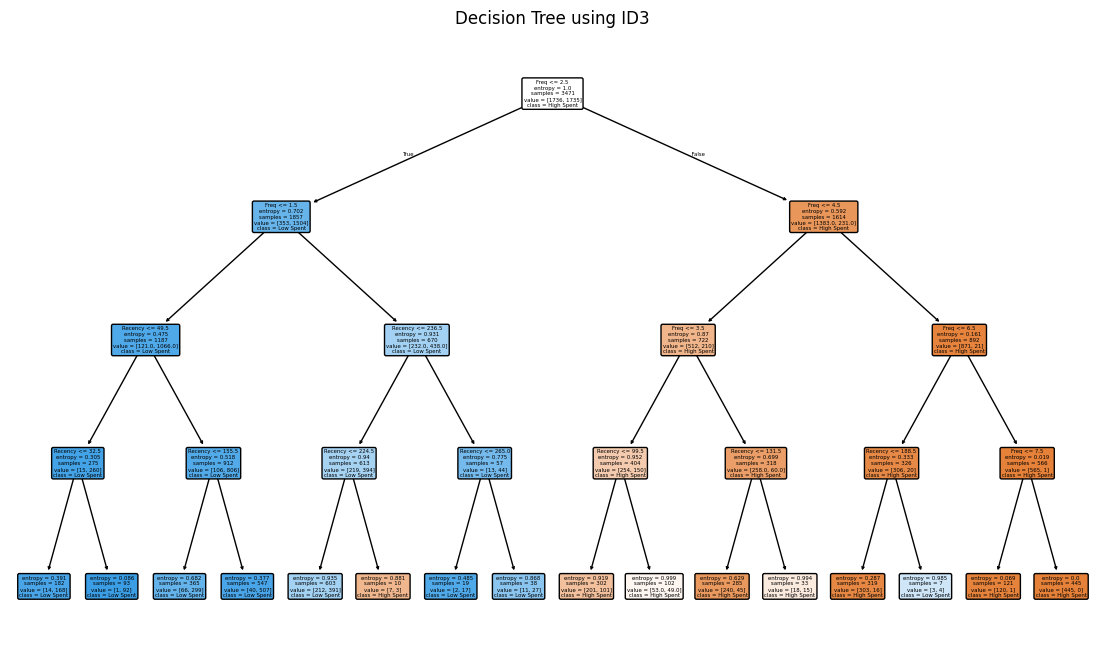


Feature Importance:
   Feature  Importance
1     Freq    0.961272
0  Recency    0.038728


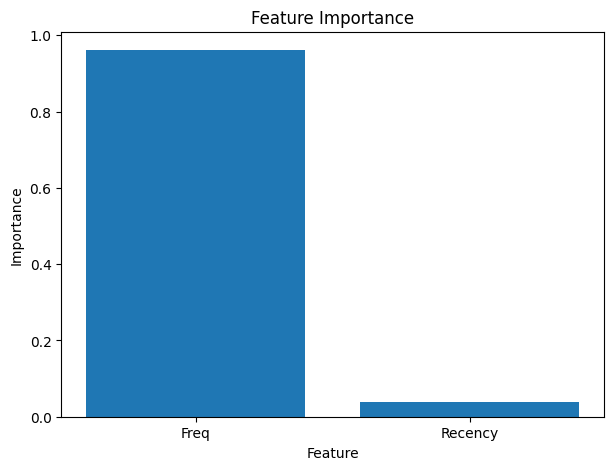

In [3]:
# 7. Separate features and target

X = rfm[["Recency", "Freq"]]
y = rfm["Segment"]


# 8. Split the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 9. Create Decision Tree using ID3

from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)


# 10. Train the model

model.fit(X_train, y_train)


# 11. Make predictions

y_pred = model.predict(X_test)


# 12. Evaluate the model

from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# 13. Visualize the Decision Tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree using ID3")
plt.show()


# 14. Feature Importance

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(importance)


# 15. Plot Feature Importance

plt.figure(figsize=(7, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature Importance")

plt.show()